In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

DATA_PATH = "../data/raw/student_mental_health.csv"
TARGET = "Mental_Health_Risk"

df = pd.read_csv(DATA_PATH)
df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [2]:
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)

df.info()
display(df.sample(5, random_state=42))

Shape: (2000, 17)

Data types:
Student_ID                         object
Age                                 int64
Gender                             object
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                  object
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                      object
Diet_Quality                       object
Previous_Mental_Health_History     object
Mental_Health_Risk                 object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
1860,STU1861,21,Male,3,8.2,20.2,2.28,5.6,6.9,Low,7.2,6.3,86.1,No,Average,No,Low
353,STU0354,21,Female,2,7.6,27.6,2.55,5.3,7.2,High,9.2,7.7,84.5,Yes,Good,Yes,Medium
1333,STU1334,24,Female,3,5.8,17.1,2.44,6.4,8.8,Moderate,2.5,8.2,83.8,Yes,Average,No,Low
905,STU0906,21,Male,2,9.4,22.0,3.35,6.0,7.6,Moderate,NaN,8.7,80.3,No,Average,Yes,Low
1289,STU1290,17,Male,2,6.3,26.8,2.43,4.1,5.6,Low,5.5,7.2,76.9,Yes,Poor,No,Medium


In [3]:
num_cols = df.select_dtypes(include="number").columns.drop(TARGET, errors="ignore")
cat_cols = df.select_dtypes(exclude="number").columns.drop(TARGET, errors="ignore")

print("Negative values per numeric column:")
print((df[num_cols] < 0).sum()[lambda s: s > 0])
print("\nMin / Max:")
print(df[num_cols].agg(["min", "max"]).T)

for col in cat_cols:
    print(f"\n{col}: {df[col].unique()}")

Negative values per numeric column:
Series([], dtype: int64)

Min / Max:
                       min     max
Age                   17.0   29.00
Year_of_Study          1.0    5.00
Sleep_Hours            3.3   10.00
Study_Hours_Per_Week   2.4   38.30
GPA                    1.5    3.66
Social_Media_Hours     2.1   10.00
Screen_Time_Hours      3.3   14.00
Financial_Stress       1.4   10.00
Family_Support         1.7    9.90
Attendance_Rate       54.4  100.00

Student_ID: ['STU0001' 'STU0002' 'STU0003' ... 'STU1998' 'STU1999' 'STU2000']

Gender: ['Male' 'Female' 'Non-binary']

Physical_Activity: ['Moderate' 'Low' 'High']

Part_Time_Job: ['No' 'Yes']

Diet_Quality: ['Poor' 'Average' nan 'Good']

Previous_Mental_Health_History: ['No' 'Yes']


In [ ]:
missing = pd.DataFrame({
    "Count": df.isna().sum(),
    "Percentage": (df.isna().mean() * 100).round(2)
})
invalid_screen = df["Screen_Time_Hours"] < df["Social_Media_Hours"]

print("Missing values:")
display(missing[missing["Count"] > 0])

print("Duplicated rows:", df.duplicated().sum())
print("Missing target:", df[TARGET].isna().sum())
print("St values :", invalid_screen.sum())

Missing values:


,Count,Percentage
Sleep_Hours,62,3.10
GPA,38,1.90
Social_Media_Hours,58,2.90
Financial_Stress,91,4.55
Family_Support,54,2.70
Attendance_Rate,47,2.35
Diet_Quality,69,3.45


Duplicated rows: 0
Missing target: 0
St values corrected: 37


Outliers per column:
Social_Media_Hours      20
Attendance_Rate         12
GPA                      9
Study_Hours_Per_Week     7
Screen_Time_Hours        7
Age                      4
Sleep_Hours              2
Year_of_Study            0
Financial_Stress         0
Family_Support           0
dtype: int64


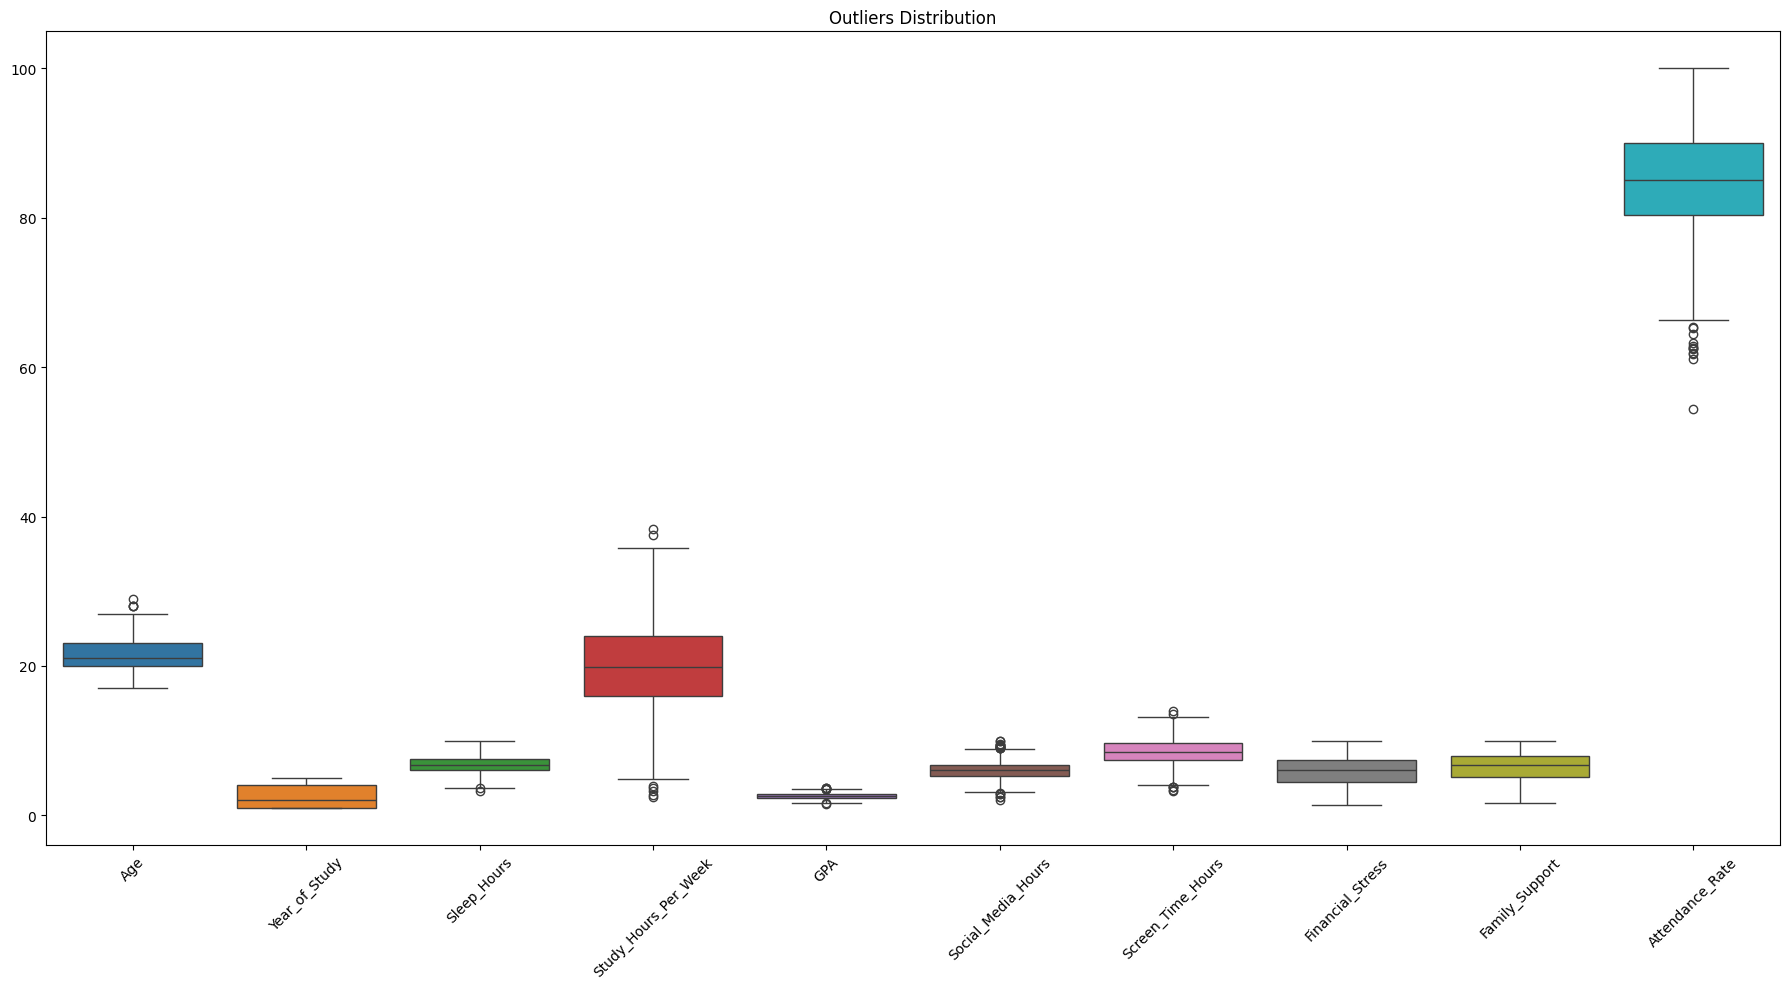

In [5]:
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (df[num_cols] < Q1 - 1.5 * IQR) |
    (df[num_cols] > Q3 + 1.5 * IQR)
)

print("Outliers per column:")
print(outliers.sum().sort_values(ascending=False))

plt.figure(figsize=(18, 10))
sns.boxplot(data=df[num_cols])
plt.title("Outliers Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
print("Numerical statistics:")
display(df.describe().T)

print("Categorical statistics:")
display(df.describe(include="object").T)

Numerical statistics:


,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


Categorical statistics:


,count,unique,top,freq
Student_ID,2000,2000,STU0001,1
Gender,2000,3,Female,971
Physical_Activity,2000,3,Moderate,906
Part_Time_Job,2000,2,No,1289
Diet_Quality,1931,3,Average,860
Previous_Mental_Health_History,2000,2,No,1408
Mental_Health_Risk,2000,3,High,680


Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64
Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


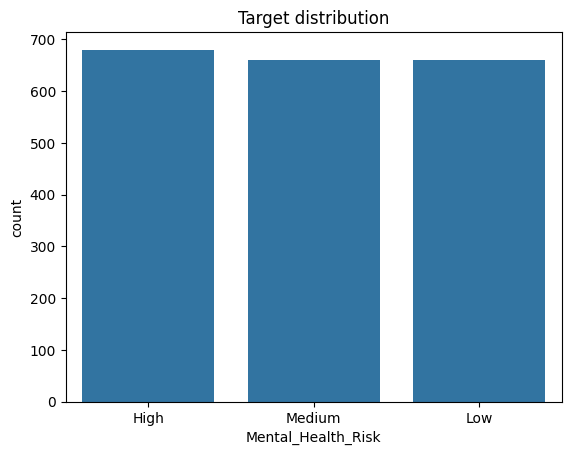

In [7]:
counts = df[TARGET].value_counts()
print(counts)
print((df[TARGET].value_counts(normalize=True) * 100).round(2))

sns.countplot(x=TARGET, data=df, order=counts.index)
plt.title("Target distribution")
plt.show()

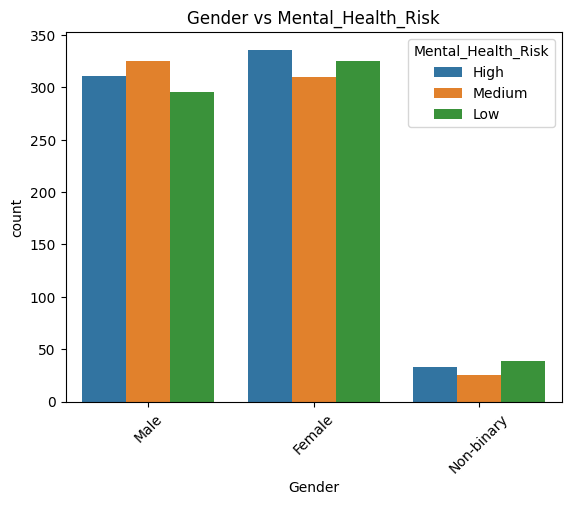

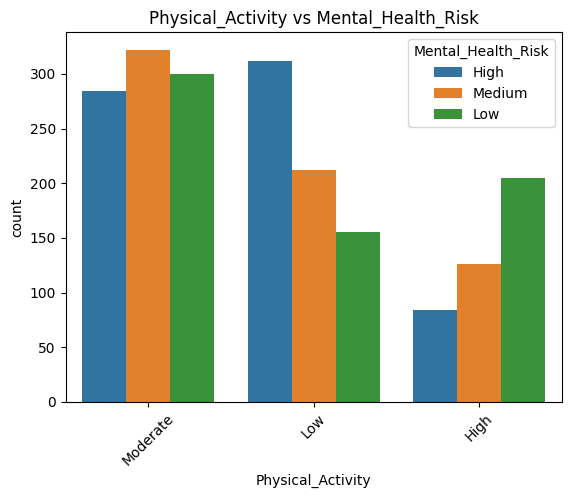

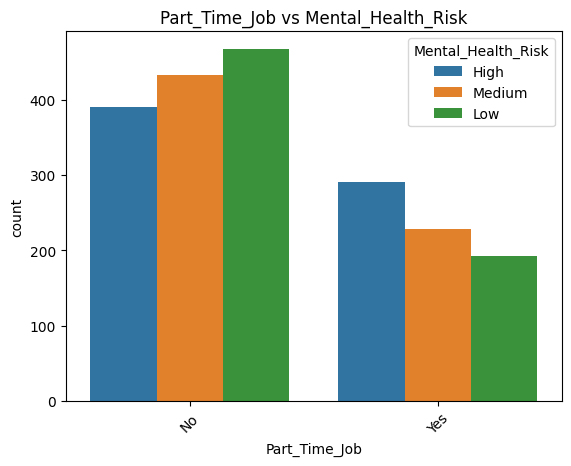

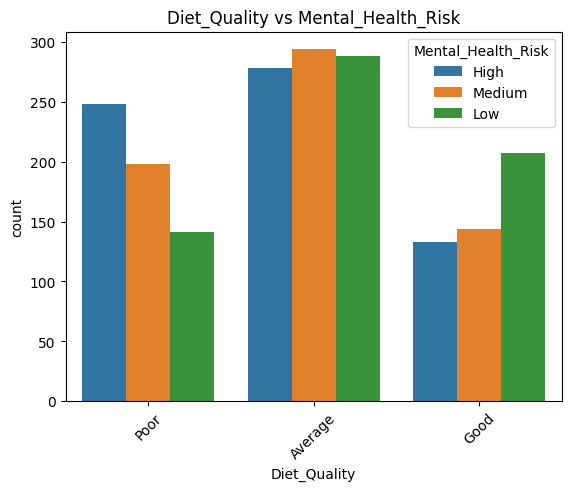

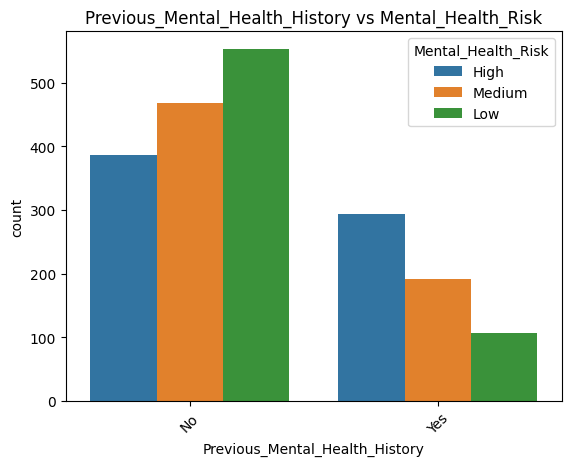

In [8]:
for col in cat_cols.drop("Student_ID", errors="ignore"):
    sns.countplot(x=col, hue=TARGET, data=df)
    plt.title(f"{col} vs {TARGET}")
    plt.xticks(rotation=45)
    plt.show()

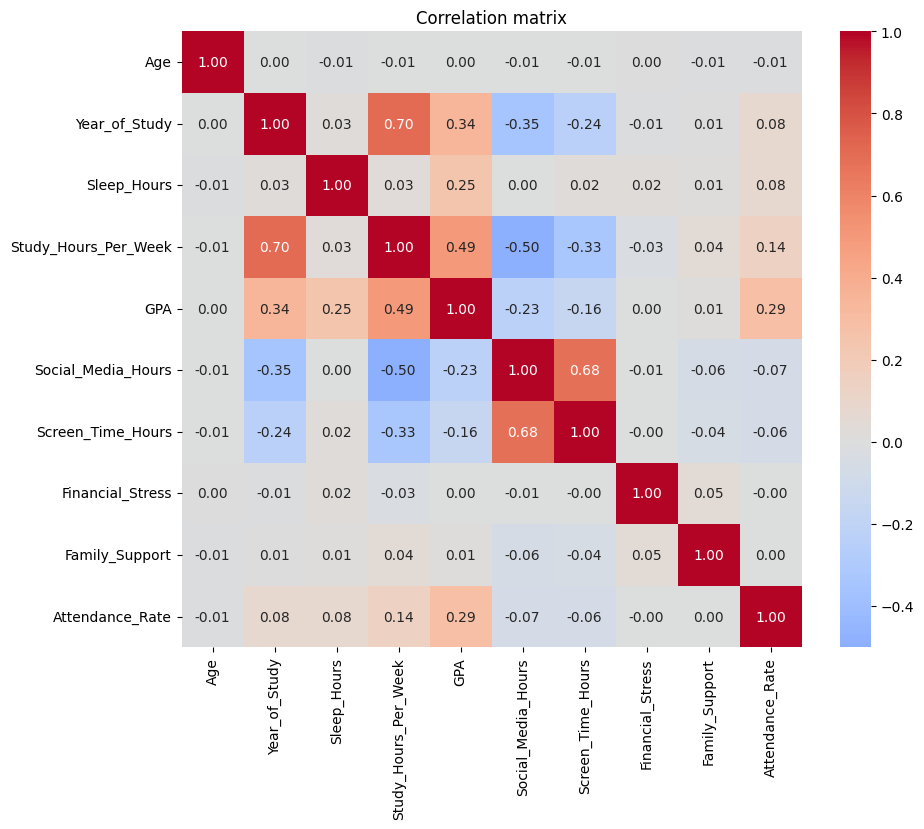

In [9]:
corr = df[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

Sleep_Hours                       0.160793
GPA                               0.074529
Financial_Stress                  0.049818
Screen_Time_Hours                 0.033114
Study_Hours_Per_Week              0.030085
Family_Support                    0.029925
Physical_Activity                 0.029587
Attendance_Rate                   0.020399
Social_Media_Hours                0.018398
Diet_Quality                      0.018190
Previous_Mental_Health_History    0.017920
Student_ID                        0.015977
Part_Time_Job                     0.009780
Year_of_Study                     0.000910
Age                               0.000000
Gender                            0.000000
dtype: float64


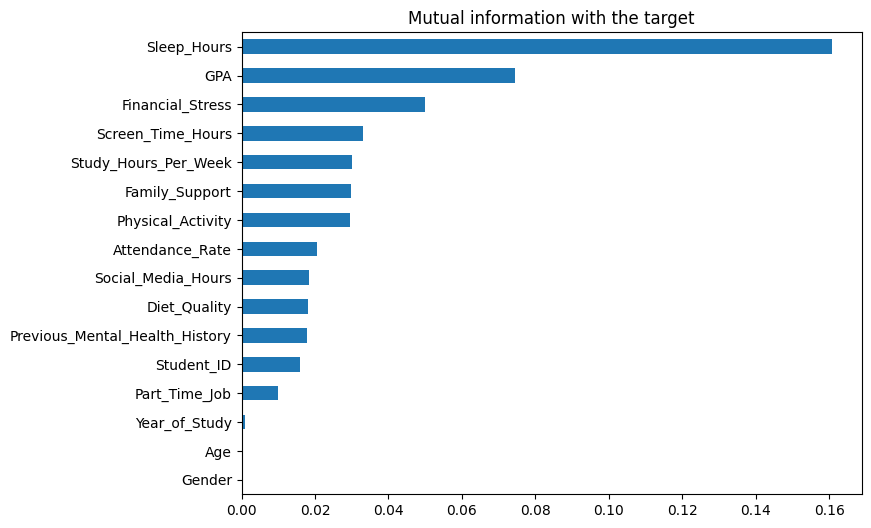

In [10]:
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET]

for col in X.columns:
    if X[col].dtype == "object":
        X[col] = X[col].astype("category").cat.codes
    X[col] = X[col].fillna(X[col].median())

scores = pd.Series(mutual_info_classif(X, y, random_state=42), index=X.columns)
scores = scores.sort_values(ascending=False)
print(scores)

scores.plot(kind="barh", figsize=(8, 6)).invert_yaxis()
plt.title("Mutual information with the target")
plt.show()

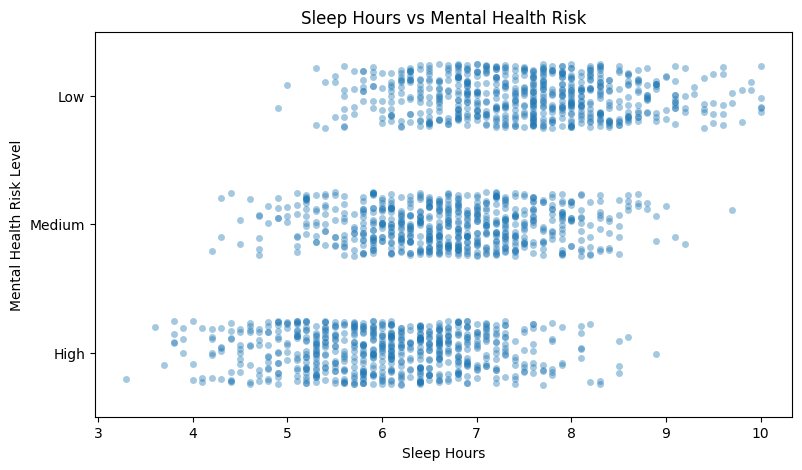

In [11]:
plt.figure(figsize=(9, 5))

sns.stripplot(
    data=df,
    x="Sleep_Hours",
    y="Mental_Health_Risk",
    order=["Low", "Medium", "High"],
    jitter=0.25,
    alpha=0.4
)

plt.title("Sleep Hours vs Mental Health Risk")
plt.xlabel("Sleep Hours")
plt.ylabel("Mental Health Risk Level")
plt.show()

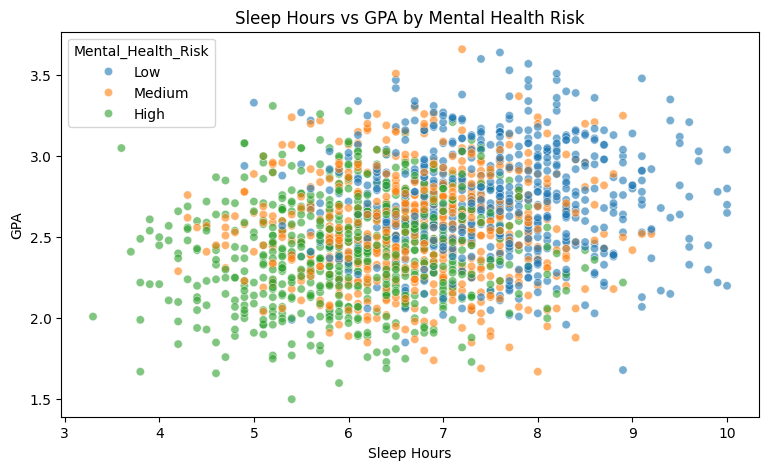

In [12]:

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Sleep_Hours",
    y="GPA",
    hue="Mental_Health_Risk",
    hue_order=["Low", "Medium", "High"],
    alpha=0.6
)

plt.title("Sleep Hours vs GPA by Mental Health Risk")
plt.xlabel("Sleep Hours")
plt.ylabel("GPA")
plt.show()
